In [2]:
import tensorflow as tf
from tensorflow import keras
import numpy as np


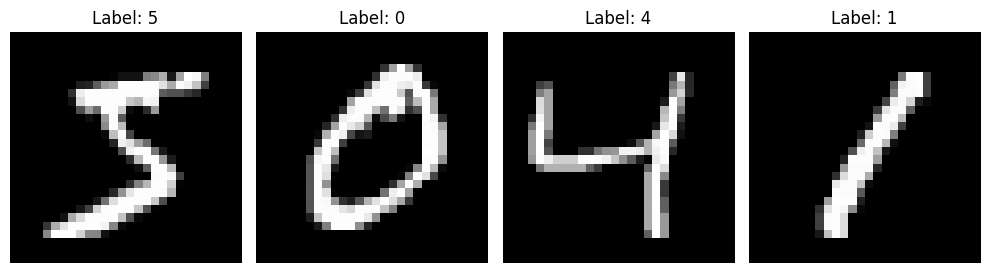

In [3]:
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Print 4 images in a row
plt.figure(figsize=(10, 5))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [4]:
num_classes = 10
input_shape = (28, 28, 1)

In [5]:
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255
# Make sure images have shape (28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)
print("x_train shape:", x_train.shape)
print(x_train.shape[0], "train samples")
print(x_test.shape[0], "test samples")


# convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

x_train shape: (60000, 28, 28, 1)
60000 train samples
10000 test samples


In [6]:
from keras import layers

In [7]:
inputs=keras.Input(shape=(input_shape))
x=layers.Conv2D(32,kernel_size=(3,3))(inputs)
x=layers.BatchNormalization()(x)
x=layers.ReLU()(x)
x=layers.Flatten()(x)
outputs=layers.Dense(num_classes, activation="softmax")(x)
model=keras.Model(inputs,outputs)

In [8]:
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 28, 28, 1)]       0         
                                                                 
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 batch_normalization (BatchN  (None, 26, 26, 32)       128       
 ormalization)                                                   
                                                                 
 re_lu (ReLU)                (None, 26, 26, 32)        0         
                                                                 
 flatten (Flatten)           (None, 21632)             0         
                                                                 
 dense (Dense)               (None, 10)                216330    
                                                             

In [9]:
batch_size = 128
epochs = 150

model.compile(loss="categorical_crossentropy", optimizer= keras.optimizers.Adam(learning_rate=0.00001), metrics=["accuracy"])

history=model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/150
422/422 [==============================] - 6s 6ms/step - loss: 1.1248 - accuracy: 0.6873 - val_loss: 0.9157 - val_accuracy: 0.8883
Epoch 2/150
422/422 [==============================] - 2s 5ms/step - loss: 0.4640 - accuracy: 0.8846 - val_loss: 0.3257 - val_accuracy: 0.9267
Epoch 3/150
422/422 [==============================] - 2s 5ms/step - loss: 0.3416 - accuracy: 0.9113 - val_loss: 0.2533 - val_accuracy: 0.9365
Epoch 4/150
422/422 [==============================] - 2s 5ms/step - loss: 0.2838 - accuracy: 0.9247 - val_loss: 0.2175 - val_accuracy: 0.9447
Epoch 5/150
422/422 [==============================] - 3s 6ms/step - loss: 0.2476 - accuracy: 0.9336 - val_loss: 0.1919 - val_accuracy: 0.9510
Epoch 6/150
422/422 [==============================] - 3s 7ms/step - loss: 0.2209 - accuracy: 0.9404 - val_loss: 0.1746 - val_accuracy: 0.9538
Epoch 7/150
422/422 [==============================] - 2s 6ms/step - loss: 0.1999 - accuracy: 0.9457 - val_loss: 0.1591 - val_accuracy: 0.9583

Epoch 58/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0302 - accuracy: 0.9942 - val_loss: 0.0592 - val_accuracy: 0.9850
Epoch 59/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0296 - accuracy: 0.9944 - val_loss: 0.0599 - val_accuracy: 0.9833
Epoch 60/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0288 - accuracy: 0.9947 - val_loss: 0.0590 - val_accuracy: 0.9847
Epoch 61/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0284 - accuracy: 0.9947 - val_loss: 0.0598 - val_accuracy: 0.9837
Epoch 62/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0278 - accuracy: 0.9949 - val_loss: 0.0606 - val_accuracy: 0.9838
Epoch 63/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0272 - accuracy: 0.9953 - val_loss: 0.0592 - val_accuracy: 0.9838
Epoch 64/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0267 - accuracy: 0.9952 - val_loss: 0.0595 - val_accuracy:

Epoch 115/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0104 - accuracy: 0.9992 - val_loss: 0.0614 - val_accuracy: 0.9845
Epoch 116/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0103 - accuracy: 0.9992 - val_loss: 0.0620 - val_accuracy: 0.9842
Epoch 117/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0100 - accuracy: 0.9992 - val_loss: 0.0620 - val_accuracy: 0.9840
Epoch 118/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0099 - accuracy: 0.9992 - val_loss: 0.0618 - val_accuracy: 0.9843
Epoch 119/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0097 - accuracy: 0.9993 - val_loss: 0.0621 - val_accuracy: 0.9845
Epoch 120/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0096 - accuracy: 0.9993 - val_loss: 0.0620 - val_accuracy: 0.9847
Epoch 121/150
422/422 [==============================] - 2s 5ms/step - loss: 0.0094 - accuracy: 0.9993 - val_loss: 0.0618 - val_ac

In [10]:
class Weibull(keras.layers.Layer):
    def __init__(self, shape, scale, **kwargs):
        super().__init__(**kwargs)
        self.shape = shape
        self.scale = scale

    def call(self, inputs):
        inputs = tf.cast(inputs, tf.float32)
        
        # Avoid division by zero or negative scale
        z = tf.math.maximum(inputs / self.scale, 0.0)

        # Weibull CDF: 1 - exp(-(z)^shape)
        weibull_cdf = 1.0 - tf.exp(-tf.pow(z, self.shape))

        # Optional: hard-zero for negative inputs (domain of Weibull CDF is x ≥ 0)
        output = tf.where(inputs < 0, 0.0, weibull_cdf)

        return output

    def get_config(self):
        config = super().get_config()
        config.update({
            "shape": self.shape,
            "scale": self.scale,
        })
        return config


In [11]:
inputs=keras.Input(shape=(input_shape))
x=layers.Conv2D(32,kernel_size=(3,3))(inputs)
x=layers.BatchNormalization()(x)
x=Weibull(shape=1.5,scale=1)(x)#2,5
x=layers.Flatten()(x)
outputs=layers.Dense(num_classes, activation="softmax")(x)
model_ray=keras.Model(inputs,outputs)

In [12]:
model_ray.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 28, 28, 1)]       0         
                                                                 
 conv2d_1 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 batch_normalization_1 (Batc  (None, 26, 26, 32)       128       
 hNormalization)                                                 
                                                                 
 weibull (Weibull)           (None, 26, 26, 32)        0         
                                                                 
 flatten_1 (Flatten)         (None, 21632)             0         
                                                                 
 dense_1 (Dense)             (None, 10)                216330    
                                                           

In [13]:
model_ray.compile(loss="categorical_crossentropy", optimizer= keras.optimizers.Adam(learning_rate=0.00001), metrics=["accuracy"])

history_ray=model_ray.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/150
422/422 [==============================] - 4s 9ms/step - loss: 1.3095 - accuracy: 0.7100 - val_loss: 1.0340 - val_accuracy: 0.8733
Epoch 2/150
422/422 [==============================] - 4s 8ms/step - loss: 0.6194 - accuracy: 0.8686 - val_loss: 0.4416 - val_accuracy: 0.9100
Epoch 3/150
422/422 [==============================] - 4s 8ms/step - loss: 0.4564 - accuracy: 0.8913 - val_loss: 0.3427 - val_accuracy: 0.9223
Epoch 4/150
422/422 [==============================] - 4s 8ms/step - loss: 0.3832 - accuracy: 0.9033 - val_loss: 0.2947 - val_accuracy: 0.9293
Epoch 5/150
422/422 [==============================] - 4s 8ms/step - loss: 0.3401 - accuracy: 0.9110 - val_loss: 0.2644 - val_accuracy: 0.9338
Epoch 6/150
422/422 [==============================] - 4s 8ms/step - loss: 0.3104 - accuracy: 0.9174 - val_loss: 0.2425 - val_accuracy: 0.9398
Epoch 7/150
422/422 [==============================] - 4s 8ms/step - loss: 0.2881 - accuracy: 0.9228 - val_loss: 0.2261 - val_accuracy: 0.9422

Epoch 58/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0756 - accuracy: 0.9816 - val_loss: 0.0796 - val_accuracy: 0.9800
Epoch 59/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0746 - accuracy: 0.9820 - val_loss: 0.0785 - val_accuracy: 0.9802
Epoch 60/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0732 - accuracy: 0.9824 - val_loss: 0.0780 - val_accuracy: 0.9798
Epoch 61/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0722 - accuracy: 0.9825 - val_loss: 0.0778 - val_accuracy: 0.9805
Epoch 62/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0711 - accuracy: 0.9827 - val_loss: 0.0773 - val_accuracy: 0.9800
Epoch 63/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0700 - accuracy: 0.9832 - val_loss: 0.0764 - val_accuracy: 0.9803
Epoch 64/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0690 - accuracy: 0.9836 - val_loss: 0.0756 - val_accuracy:

Epoch 115/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0373 - accuracy: 0.9928 - val_loss: 0.0606 - val_accuracy: 0.9832
Epoch 116/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0370 - accuracy: 0.9926 - val_loss: 0.0602 - val_accuracy: 0.9832
Epoch 117/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0365 - accuracy: 0.9930 - val_loss: 0.0602 - val_accuracy: 0.9837
Epoch 118/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0362 - accuracy: 0.9931 - val_loss: 0.0598 - val_accuracy: 0.9837
Epoch 119/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0358 - accuracy: 0.9930 - val_loss: 0.0602 - val_accuracy: 0.9835
Epoch 120/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0355 - accuracy: 0.9932 - val_loss: 0.0597 - val_accuracy: 0.9837
Epoch 121/150
422/422 [==============================] - 4s 8ms/step - loss: 0.0352 - accuracy: 0.9932 - val_loss: 0.0595 - val_ac

the value of breast cancer

| Metric   | Weibull CDF Activation | ReLU                |
| -------- | ---------------------- | ------------------- |
| RMSE     | 0.0337                 | 0.03                |
| MAE      | 0.0231                 | 0.03                |
| MAPE     | 14.22%                 | 15.73%              |

In [14]:
inputs=keras.Input(shape=(input_shape))
x=layers.Conv2D(32,kernel_size=(3,3))(inputs)
x=layers.BatchNormalization()(x)
x=tf.keras.activations.gelu(x)
x=layers.Flatten()(x)
outputs=layers.Dense(num_classes, activation="softmax")(x)
model_gelu=keras.Model(inputs,outputs)

In [15]:
model_gelu.compile(loss="categorical_crossentropy", optimizer= keras.optimizers.Adam(learning_rate=0.00001), metrics=["accuracy"])

history_gelu=model_gelu.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/150
422/422 [==============================] - 4s 8ms/step - loss: 1.0013 - accuracy: 0.7134 - val_loss: 0.8391 - val_accuracy: 0.8903
Epoch 2/150
422/422 [==============================] - 3s 8ms/step - loss: 0.4217 - accuracy: 0.8915 - val_loss: 0.3011 - val_accuracy: 0.9292
Epoch 3/150
422/422 [==============================] - 3s 8ms/step - loss: 0.3203 - accuracy: 0.9144 - val_loss: 0.2407 - val_accuracy: 0.9407
Epoch 4/150
422/422 [==============================] - 3s 8ms/step - loss: 0.2703 - accuracy: 0.9271 - val_loss: 0.2078 - val_accuracy: 0.9473
Epoch 5/150
422/422 [==============================] - 3s 8ms/step - loss: 0.2370 - accuracy: 0.9356 - val_loss: 0.1847 - val_accuracy: 0.9542
Epoch 6/150
422/422 [==============================] - 3s 8ms/step - loss: 0.2120 - accuracy: 0.9429 - val_loss: 0.1682 - val_accuracy: 0.9582
Epoch 7/150
422/422 [==============================] - 3s 8ms/step - loss: 0.1922 - accuracy: 0.9481 - val_loss: 0.1534 - val_accuracy: 0.9615

Epoch 58/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0281 - accuracy: 0.9948 - val_loss: 0.0557 - val_accuracy: 0.9855
Epoch 59/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0275 - accuracy: 0.9947 - val_loss: 0.0555 - val_accuracy: 0.9853
Epoch 60/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0268 - accuracy: 0.9952 - val_loss: 0.0549 - val_accuracy: 0.9848
Epoch 61/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0262 - accuracy: 0.9953 - val_loss: 0.0555 - val_accuracy: 0.9850
Epoch 62/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0257 - accuracy: 0.9955 - val_loss: 0.0552 - val_accuracy: 0.9853
Epoch 63/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0251 - accuracy: 0.9955 - val_loss: 0.0554 - val_accuracy: 0.9847
Epoch 64/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0246 - accuracy: 0.9956 - val_loss: 0.0549 - val_accuracy:

Epoch 115/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0090 - accuracy: 0.9994 - val_loss: 0.0577 - val_accuracy: 0.9853
Epoch 116/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0088 - accuracy: 0.9994 - val_loss: 0.0578 - val_accuracy: 0.9853
Epoch 117/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0086 - accuracy: 0.9994 - val_loss: 0.0569 - val_accuracy: 0.9857
Epoch 118/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0085 - accuracy: 0.9995 - val_loss: 0.0571 - val_accuracy: 0.9857
Epoch 119/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0083 - accuracy: 0.9994 - val_loss: 0.0575 - val_accuracy: 0.9853
Epoch 120/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0082 - accuracy: 0.9995 - val_loss: 0.0576 - val_accuracy: 0.9857
Epoch 121/150
422/422 [==============================] - 3s 8ms/step - loss: 0.0080 - accuracy: 0.9995 - val_loss: 0.0579 - val_ac

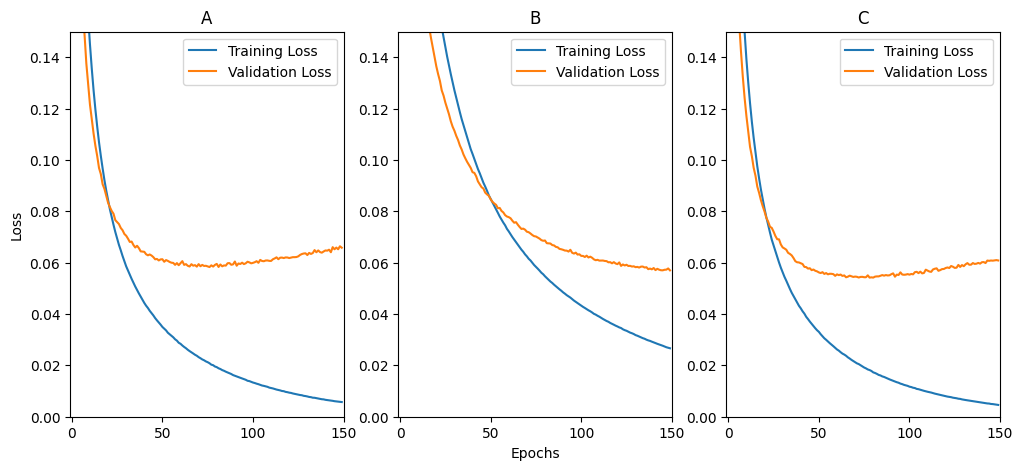

<Figure size 640x480 with 0 Axes>

In [16]:
def plot_loss_comparison2(relu_history, custom_history1,custom_history2 ):
    plt.figure(figsize=(12, 5))
    
    # Set consistent axis limits
    y_min = 0
    y_max = 0.15
    x_max = max(len(relu_history.history['loss']), 
               len(custom_history1.history['loss']),
               len(custom_history2.history['loss']))
    
    # Plot ReLU results
    plt.subplot(1, 3, 1)
    plt.plot(relu_history.history['loss'], label='Training Loss')
    plt.plot(relu_history.history['val_loss'], label='Validation Loss')
    plt.title('A')
    plt.ylabel('Loss')
    plt.ylim(y_min, y_max)
    plt.xlim(-1, x_max)
    plt.legend()
    
    # Plot Custom activation results
    plt.subplot(1, 3, 2)
    plt.plot(custom_history1.history['loss'], label='Training Loss')
    plt.plot(custom_history1.history['val_loss'], label='Validation Loss')
    plt.title('B')
    plt.xlabel('Epochs')
    plt.ylim(y_min, y_max)
    plt.xlim(-1, x_max)
    plt.legend()
    
    plt.subplot(1, 3, 3)
    plt.plot(custom_history2.history['loss'], label='Training Loss')
    plt.plot(custom_history2.history['val_loss'], label='Validation Loss')
    plt.title('C')

    plt.ylim(y_min, y_max)
    plt.xlim(-1, x_max)
    plt.legend()
    plt.show()

    plt.tight_layout()
    plt.show()

# Usage
plot_loss_comparison2(history,history_ray,history_gelu)

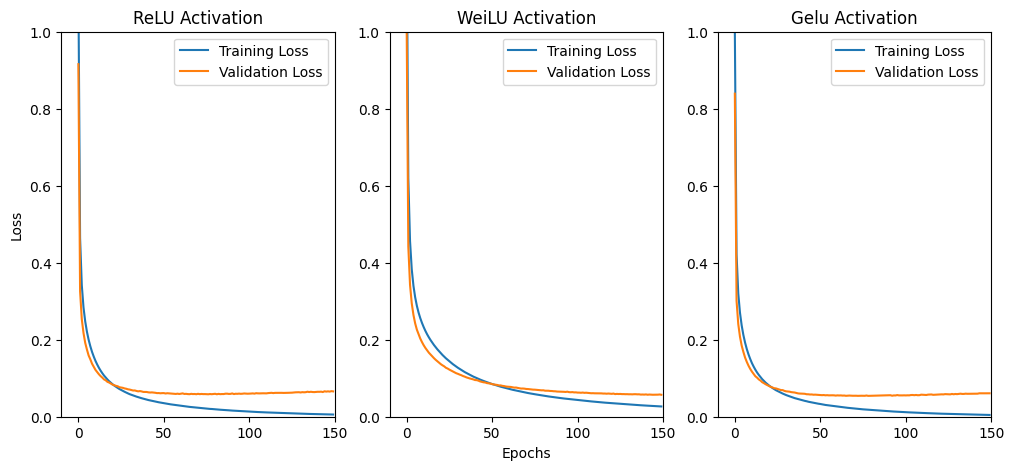

<Figure size 640x480 with 0 Axes>

In [17]:
def plot_loss_comparison(relu_history, custom_history1,custom_history2 ):
    plt.figure(figsize=(12, 5))
    
    # Set consistent axis limits
    y_min = 0
    y_max = 1
    x_max = max(len(relu_history.history['loss']), 
               len(custom_history1.history['loss']),
               len(custom_history2.history['loss']))
    
    # Plot ReLU results
    plt.subplot(1, 3, 1)
    plt.plot(relu_history.history['loss'], label='Training Loss')
    plt.plot(relu_history.history['val_loss'], label='Validation Loss')
    plt.title('ReLU Activation')
    plt.ylabel('Loss')
    plt.ylim(y_min, y_max)
    plt.xlim(-10, x_max)
    plt.legend()
    
    # Plot Custom activation results
    plt.subplot(1, 3, 2)
    plt.plot(custom_history1.history['loss'], label='Training Loss')
    plt.plot(custom_history1.history['val_loss'], label='Validation Loss')
    plt.title('WeiLU Activation')
    plt.xlabel('Epochs')
    plt.ylim(y_min, y_max)
    plt.xlim( -10, x_max)
    plt.legend()
    
    plt.subplot(1, 3, 3)
    plt.plot(custom_history2.history['loss'], label='Training Loss')
    plt.plot(custom_history2.history['val_loss'], label='Validation Loss')
    plt.title('Gelu Activation')
    plt.ylim(y_min, y_max)
    plt.xlim(-10, x_max)
    plt.legend()
    plt.show()

    plt.tight_layout()
    plt.show()

# Usage
plot_loss_comparison(history,history_ray,history_gelu)

In [20]:
score_relu = model.evaluate(x_test, y_test, verbose=0)
score_weilu = model_ray.evaluate(x_test, y_test, verbose=0)
score_gelu = model_gelu.evaluate(x_test, y_test, verbose=0)


Relu accuracy: [0.06838440895080566, 0.9801999926567078]
Weilu accuracy: [0.06277032196521759, 0.9803000092506409]
Gelu accuracy: [0.06391418725252151, 0.9817000031471252]


In [21]:
print("Relu accuracy:", score_relu)
print("Weilu accuracy:", score_weilu)
print("Gelu accuracy:", score_gelu)

Relu accuracy: [0.06838440895080566, 0.9801999926567078]
Weilu accuracy: [0.06277032196521759, 0.9803000092506409]
Gelu accuracy: [0.06391418725252151, 0.9817000031471252]
